## Fine-tune TrOCR on the IAM Handwriting Database

In this notebook, we are going to fine-tune a pre-trained TrOCR model on the [IAM Handwriting Database](https://fki.tic.heia-fr.ch/databases/iam-handwriting-database), a collection of annotated images of handwritten text.

We will do this using the new `VisionEncoderDecoderModel` class, which can be used to combine any image Transformer encoder (such as ViT, BEiT) with any text Transformer as decoder (such as BERT, RoBERTa, GPT-2). TrOCR is an instance of this, as it has an encoder-decoder architecture, with the weights of the encoder initialized from a pre-trained BEiT, and the weights of the decoder initialized from a pre-trained RoBERTa. The weights of the cross-attention layer were randomly initialized, before the authors pre-trained the model further on millions of (partially synthetic) annotated images of handwritten text.

This figure gives a good overview of the model (from the original paper):

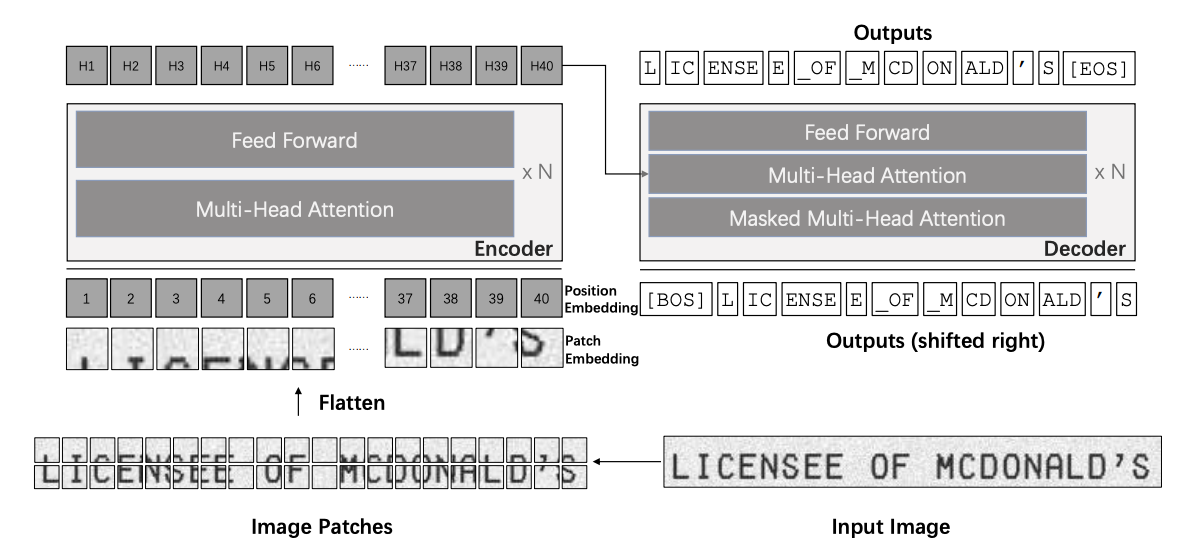

* TrOCR paper: https://arxiv.org/abs/2109.10282
* TrOCR documentation: https://huggingface.co/transformers/master/model_doc/trocr.html


Note that Patrick also wrote a very good [blog post](https://huggingface.co/blog/warm-starting-encoder-decoder) on warm-starting encoder-decoder models (which is what the TrOCR authors did). This blog post was very helpful for me to create this notebook.

We will fine-tune the model using the Seq2SeqTrainer, which is a subclass of the 🤗 Trainer that lets you compute generative metrics such as BLEU, ROUGE, etc by doing generation (i.e. calling the `generate` method) inside the evaluation loop.



## Set-up environment

First, let's install the required libraries:
* Transformers (for the TrOCR model)
* Datasets & Jiwer (for the evaluation metric)

We will not be using HuggingFace Datasets in this notebook for data preprocessing, we will just create a good old basic PyTorch Dataset.

In [1]:
!pip install transformers
!pip install --upgrade huggingface_hub
!pip install datasets jiwer evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.8/447.8 kB 16.1 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.25.1
    Uninstalling huggingface-hub-0.25.1:
      Successfully uninstalled huggingface-hub-0.25.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 24.2 MB/s eta 0:00:00a 0:00:01


## Prepare data

We first download the data. Here, I'm just using the IAM test set, as this was released by the TrOCR authors in the unilm repository. It can be downloaded from [this page](https://github.com/microsoft/unilm/tree/master/trocr).

Let's make a [regular PyTorch dataset](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html). We first create a Pandas dataframe with 2 columns. Each row consists of the file name of an image, and the corresponding text.

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
from transformers import TrOCRProcessor
from transformers import VisionEncoderDecoderModel
import torch
from torch.utils.data import Dataset
from PIL import Image

from huggingface_hub import login
access_token = user_secrets.get_secret("HF_Token")
login=login(token=access_token)

In [2]:
from zipfile import ZipFile
import os

def unzip(save_path):
    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

unzip('Synthetic_Data.zip')


Invalid file. [Errno 2] No such file or directory: 'Synthetic_Data.zip'


In [4]:
import pandas as pd

def import_dataset(path):
  df = pd.read_fwf(path, header=None)
  df.rename(columns={0: "file_name", 1: "text"}, inplace=True)
  df = df[['file_name','text']]
  df['file_name'] = df['file_name'].apply(lambda x: x + 'g' if x.endswith('jp') else x)
  return(df)

train_df = import_dataset('/kaggle/input/real-small/Archive/train.tsv')
train_df.head()

test_df = import_dataset('/kaggle/input/real-small/Archive/test.tsv')
test_df.head()

,file_name,text
0,01-4.jpg,රැකවලා විහින් අමාරුවේ
1,01-6.jpg,ටෝනි ඇබට් අභියෝගය භාරගනී
2,02-2.jpg,රටවල් කිහිපයක් උතුරු කොරියාවට එරෙහිව නව සම්බාධ...
3,02-6.jpg,රට ගොඩනැගීමට ජනාධිපතිතුමාට යම් කාලයක් ලබා දෙන්න
4,13-4.jpg,වරායේ නැගෙනහිර පර්යන්තයේ දෙවන අදියරේ ඉදිකිරීම්...


We split up the data into training + testing, using sklearn's `train_test_split` function.

Each element of the dataset should return 2 things:
* `pixel_values`, which serve as input to the model.
* `labels`, which are the `input_ids` of the corresponding text in the image.

We use `TrOCRProcessor` to prepare the data for the model. `TrOCRProcessor` is actually just a wrapper around a `ViTFeatureExtractor` (which can be used to resize + normalize images) and a `RobertaTokenizer` (which can be used to encode and decode text into/from `input_ids`).

In [5]:
import torchvision.transforms as transforms
# Augmentations.
train_transforms = transforms.Compose([
    transforms.ColorJitter(brightness=.5, hue=.3),
    transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 5)),
])

In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class IAMDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # get file name + text
        file_name = self.df['file_name'][idx]
        if ".jpg" not in file_name:
          file_name = (file_name.split(".")[0]) + ".jpg"
        text = self.df['text'][idx]
        # prepare image (i.e. resize + normalize)
        image = Image.open(self.root_dir + file_name).convert("RGB")
        image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors="pt").pixel_values
        # add labels (input_ids) by encoding the text
        labels = self.processor.tokenizer(text,
                                          padding="max_length",
                                          max_length=self.max_target_length).input_ids
        # important: make sure that PAD tokens are ignored by the loss function
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]

        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding

Let's initialize the training and evaluation datasets:

In [12]:
from transformers import TrOCRProcessor

processor = TrOCRProcessor.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")
train_dataset = IAMDataset(root_dir='/kaggle/input/real-small/Archive/train/',
                           df=train_df,
                           processor=processor)
eval_dataset = IAMDataset(root_dir='/kaggle/input/real-small/Archive/test/',
                           df=test_df,
                           processor=processor)

In [13]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(eval_dataset))

Number of training examples: 92
Number of validation examples: 24


Let's verify an example from the training dataset:

In [14]:
encoding = train_dataset[0]
for k,v in encoding.items():
  print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


We can also check the original image and decode the labels:

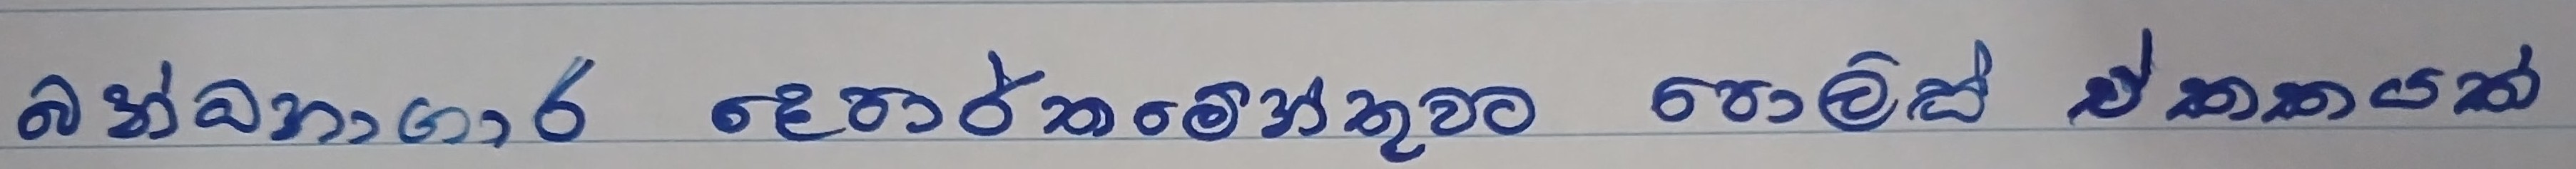

In [15]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
image

In [16]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

බන්ධනාගාර දෙපාර්තමේන්තුවට පොලිස් ඒකකයක්


## Train a model

Here, we initialize the TrOCR model from its pretrained weights. Note that the weights of the language modeling head are already initialized from pre-training, as the model was already trained to generate text during its pre-training stage. Refer to the paper for details.

In [17]:
from transformers import VisionEncoderDecoderModel

model = VisionEncoderDecoderModel.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Handwritten")

Importantly, we need to set a couple of attributes, namely:
* the attributes required for creating the `decoder_input_ids` from the `labels` (the model will automatically create the `decoder_input_ids` by shifting the `labels` one position to the right and prepending the `decoder_start_token_id`, as well as replacing ids which are -100 by the pad_token_id)
* the vocabulary size of the model (for the language modeling head on top of the decoder)
* beam-search related parameters which are used when generating text.

In [14]:
# set special tokens used for creating the decoder_input_ids from the labels
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# make sure vocab size is set correctly
model.config.vocab_size = model.config.decoder.vocab_size

# set beam search parameters
model.config.eos_token_id = processor.tokenizer.sep_token_id
model.config.max_length = 64
model.config.early_stopping = True
model.config.no_repeat_ngram_size = 3
model.config.length_penalty = 2.0
model.config.num_beams = 4

Next, we can define some training hyperparameters by instantiating the `training_args`. Note that there are many more parameters, all of which can be found in the [documentation](https://huggingface.co/transformers/main_classes/trainer.html#seq2seqtrainingarguments). You can for example decide what the batch size is for training/evaluation, whether to use mixed precision training (lower memory), the frequency at which you want to save the model, etc.

In [15]:
class TrainingConfig:
    BATCH_SIZE:    int = 8
    EPOCHS:         int = 20
    LEARNING_RATE: float = 0.00005

In [16]:
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    eval_strategy='steps',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=True,
    output_dir="./model_training/",
    logging_steps=2,
    save_steps=100,
    eval_steps=50,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS,
    push_to_hub=True,
    hub_model_id = "ds1219/Pandithaya-TrOCR-Sinhala-Handwritten",
    hub_private_repo=True,
    resume_from_checkpoint=True
)

We will evaluate the model on the Character Error Rate (CER), which is available in HuggingFace Datasets (see [here](https://huggingface.co/metrics/cer)).

In [18]:
import evaluate

cer_metric = evaluate.load('cer')

ModuleNotFoundError: No module named 'evaluate'

The compute_metrics function takes an `EvalPrediction` (which is a NamedTuple) as input, and should return a dictionary. The model will return an EvalPrediction at evaluation, which consists of 2 things:
* predictions: the predictions by the model.
* label_ids: the actual ground-truth labels.

In [18]:
def compute_metrics(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    cer = cer_metric.compute(predictions=pred_str, references=label_str)

    return {"cer": cer}

Let's train! We also provide the `default_data_collator` to the Trainer, which is used to batch together examples.

Note that evaluation takes quite a long time, as we're using beam search for decoding, which requires several forward passes for a given example.

In [19]:
from transformers import default_data_collator

# instantiate trainer
trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.feature_extractor,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=default_data_collator,
)

res = trainer.train()

/opt/conda/lib/python3.10/site-packages/transformers/models/trocr/processing_trocr.py:137: FutureWarning: `feature_extractor` is deprecated and will be removed in v5. Use `image_processor` instead.
  warnings.warn(
/tmp/ipykernel_30/2990929960.py:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(
/opt/conda/lib/python3.10/site-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


Step,Training Loss,Validation Loss,Cer
50,0.301000,7.660985,0.776042
100,0.032600,7.573857,0.763542
150,0.113500,7.769871,0.780208
200,0.044300,7.627484,0.757292


/opt/conda/lib/python3.10/site-packages/transformers/generation/utils.py:1493: UserWarning: You have modified the pretrained model configuration to control generation. This is a deprecated strategy to control generation and will be removed in v5. Please use and modify the model generation configuration (see https://huggingface.co/docs/transformers/generation_strategies#default-text-generation-configuration )
  warnings.warn(
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Trainer.processing_class instead.
Trainer.tokenizer is now deprecated. You should use Tra

## Inference

Note that after training, you can easily load the model using the .`from_pretrained(output_dir)` method.

For inference on new images, I refer to my inference notebook, that can also be found in my [Transformers Tutorials repository](https://github.com/NielsRogge/Transformers-Tutorials) on Github.

In [4]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [83]:
processor = TrOCRProcessor.from_pretrained('Ransaka/TrOCR-Sinhala')
model = VisionEncoderDecoderModel.from_pretrained('Ransaka/TrOCR-Sinhala')
model.to(device)

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_fea

In [85]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [86]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [88]:
image = read_and_show('/kaggle/input/real-small/Archive/train/01-1.jpg')
text = OCR(image)
print(text)

කඩවත පෙරේරා මෙටොර්කා පාර, මාර්තුට ටාන්ස් තරගයක්


In [ ]:
trained_model.push_to_hub("ds1219/Pandithaya-TrOCR-Sinhala-Printed")

# Evaluate

In [26]:
test_df = import_dataset('/kaggle/input/real-small/Archive/test.tsv')
test_df.head()

,file_name,text
0,01-4.jpg,රැකවලා විහින් අමාරුවේ
1,01-6.jpg,ටෝනි ඇබට් අභියෝගය භාරගනී
2,02-2.jpg,රටවල් කිහිපයක් උතුරු කොරියාවට එරෙහිව නව සම්බාධ...
3,02-6.jpg,රට ගොඩනැගීමට ජනාධිපතිතුමාට යම් කාලයක් ලබා දෙන්න
4,13-4.jpg,වරායේ නැගෙනහිර පර්යන්තයේ දෙවන අදියරේ ඉදිකිරීම්...


In [43]:
from transformers import VisionEncoderDecoderModel
from transformers import TrOCRProcessor, AutoTokenizer, ViTImageProcessor
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#model = VisionEncoderDecoderModel.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Handwritten")
#processor = TrOCRProcessor.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")

#processor = TrOCRProcessor.from_pretrained('Ransaka/TrOCR-Sinhala')
#model = VisionEncoderDecoderModel.from_pretrained('Ransaka/TrOCR-Sinhala')

#model = VisionEncoderDecoderModel.from_pretrained("kavg/TrOCR-SIN-DeiT-Handwritten")
#tokenizer = AutoTokenizer.from_pretrained('NLPC-UOM/SinBERT-large')
#feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
#processor = TrOCRProcessor(image_processor=feature_extractor, tokenizer=tokenizer)

model = VisionEncoderDecoderModel.from_pretrained("kavg/TrOCR-SIN-Handwritten")
tokenizer = AutoTokenizer.from_pretrained('NLPC-UOM/SinBERT-large')
feature_extractor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
processor = TrOCRProcessor(image_processor=feature_extractor, tokenizer=tokenizer)
model.to(device)

config.json:   0%|          | 0.00/77.8k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/963M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_featur

In [44]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class IAMDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # get file name + text 
        file_name = self.df['file_name'][idx]
        text = self.df['text'][idx]
        # some file names end with jp instead of jpg, the two lines below fix this
        if ".jpg" not in file_name:
          file_name = (file_name.split(".")[0]) + ".jpg"
        # prepare image (i.e. resize + normalize)
        image = Image.open(self.root_dir + file_name).convert("RGB")
        pixel_values = self.processor(image, return_tensors="pt").pixel_values
        # add labels (input_ids) by encoding the text
        labels = self.processor.tokenizer(text, 
                                          padding="max_length", 
                                          max_length=self.max_target_length).input_ids
        # important: make sure that PAD tokens are ignored by the loss function
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]

        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding
        
test_dataset = IAMDataset(root_dir='/kaggle/input/real-small/Archive/test/',
                           df=test_df,
                           processor=processor)

from torch.utils.data import DataLoader

test_dataloader = DataLoader(test_dataset, batch_size=8)
batch = next(iter(test_dataloader))
for k,v in batch.items():
  print(k, v.shape)

labels = batch["labels"]
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.batch_decode(labels, skip_special_tokens=True)
label_str

pixel_values torch.Size([8, 3, 224, 224])
labels torch.Size([8, 128])


['රැකවලා විහින් අමාරුවේ',
 'ටෝනි ඇබට් අභියෝගය භාරගනී',
 'රටවල් කිහිපයක් උතුරු කොරියාවට එරෙහිව නව සම්බාධක පනවයි',
 'රට ගොඩනැගීමට ජනාධිපතිතුමාට යම් කාලයක් ලබා දෙන්න',
 'වරායේ නැගෙනහිර පර්යන්තයේ දෙවන අදියරේ ඉදිකිරීම් අරඹයි',
 'වතුකම්කරුවන් ඉන්ධන පිරවුම්හල වටලයි',
 'මලියදේවේ ළඟ ගුරු උද්ඝෝෂණයක්',
 'පළාත් කිහිපයකට වැසිබර කාලගුණයක්']

In [45]:
import evaluate

cer = evaluate.load('cer')

In [46]:
from tqdm.notebook import tqdm

print("Running evaluation...")

for batch in tqdm(test_dataloader):
    # predict using generate
    pixel_values = batch["pixel_values"].to(device)
    outputs = model.generate(pixel_values)

    # decode
    pred_str = processor.batch_decode(outputs, skip_special_tokens=True)
    labels = batch["labels"]
    labels[labels == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels, skip_special_tokens=True)

    # add batch to metric
    cer.add_batch(predictions=pred_str, references=label_str)

final_score = cer.compute()

Running evaluation...


  0%|          | 0/3 [00:00<?, ?it/s]

In [47]:
print("Character error rate on test set:", final_score)

Character error rate on test set: 0.913312693498452
